In [15]:
import sklearn
import shap
import pandas as pd
print("Scikit-learn version:", sklearn.__version__)
print("SHAP version:", shap.__version__)
print("Setup successful!")

Scikit-learn version: 1.9.1
SHAP version: 0.54.1
Setup successful!


In [16]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer

# 1. Load the dataset
data = load_breast_cancer()

# 2. Convert to a pandas DataFrame
# The dataset has 'data' (features) and 'target' (0 or 1)
df = pd.DataFrame(data.data, columns=data.feature_names)

# 3. Add the target column
# 0 = Malignant (cancerous), 1 = Benign (non-cancerous)
df['target'] = data.target

# 4. Rename the target for readability in our charts later
df['target_label'] = df['target'].map({0: 'Malignant', 1: 'Benign'})

# 5. Display the first 5 rows
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


In [17]:
# Check for missing values and data types
print("Missing values per column:", df.isnull().sum().sum())
print("\nClass distribution:")
print(df['target_label'].value_counts())

Missing values per column: 0

Class distribution:
target_label
Benign       357
Malignant    212
Name: count, dtype: int64


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8080\3559286214.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='target_label', palette='Set2')


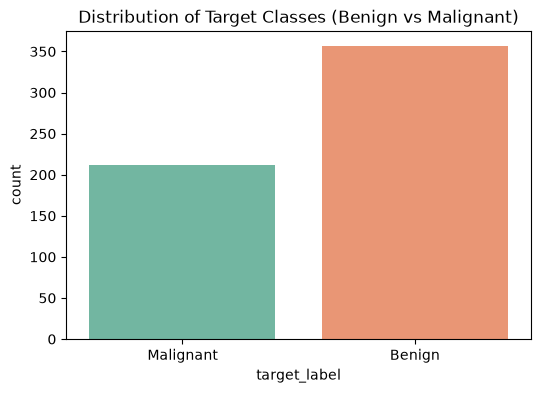

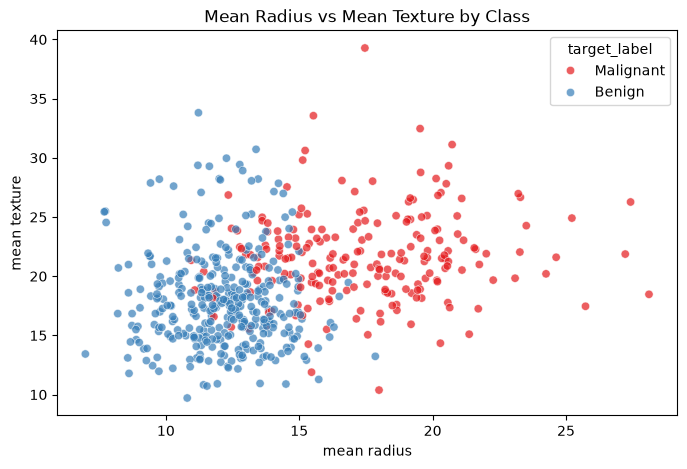

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Visualize the target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='target_label', palette='Set2')
plt.title('Distribution of Target Classes (Benign vs Malignant)')
plt.show()

# 2. Visualize two key features to see if they separate the classes
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='mean radius', y='mean texture', hue='target_label', palette='Set1', alpha=0.7)
plt.title('Mean Radius vs Mean Texture by Class')
plt.show()

In [19]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Define features (X) and target (y)
# We drop the 'target' and 'target_label' columns because those are what we are predicting
X = df.drop(columns=['target', 'target_label'])
y = df['target']

# 2. Split the data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Initialize and train the XGBoost model
model = XGBClassifier(random_state=42, eval_metric='logloss')
model.fit(X_train, y_train)

# 4. Make predictions and evaluate
y_pred = model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Malignant', 'Benign']))

Accuracy: 0.9561

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.97      0.90      0.94        42
      Benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [20]:
import shap

# 1. Create the SHAP explainer for our XGBoost model
# TreeExplainer is optimized for tree-based models like XGBoost
explainer = shap.TreeExplainer(model)

# 2. Calculate SHAP values for the test set
shap_values = explainer.shap_values(X_test)

print("SHAP values calculated successfully!")
print("Shape of SHAP values:", shap_values.shape)

SHAP values calculated successfully!
Shape of SHAP values: (114, 30)


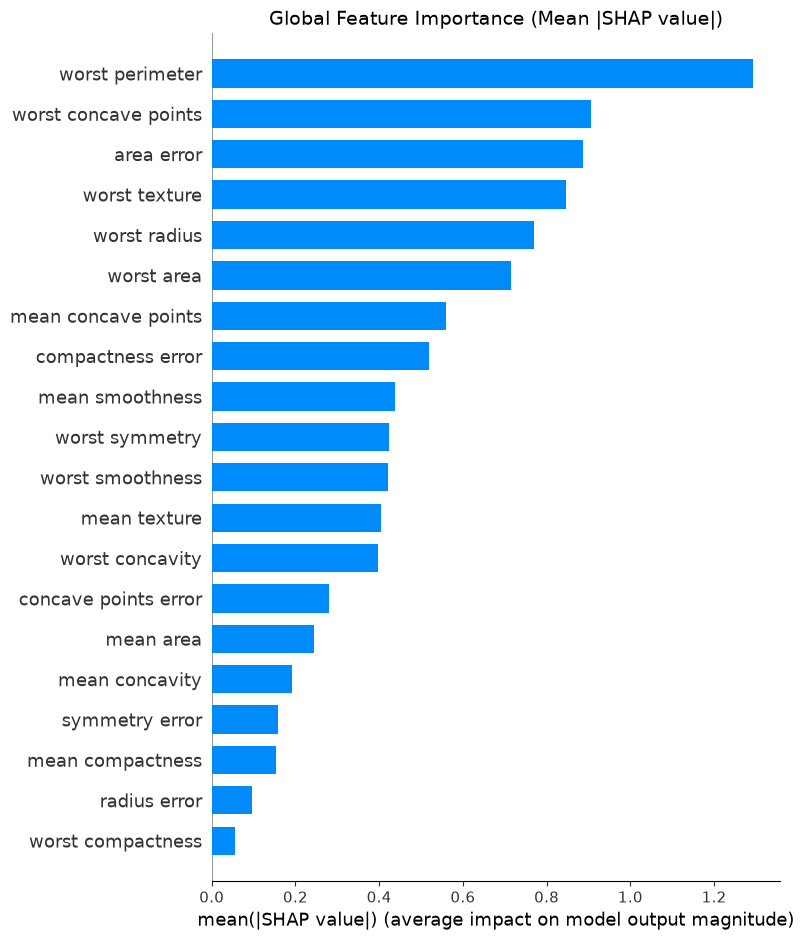

In [21]:
# 3. Global Explanation: SHAP Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("Global Feature Importance (Mean |SHAP value|)", fontsize=14)
plt.tight_layout()
plt.show()

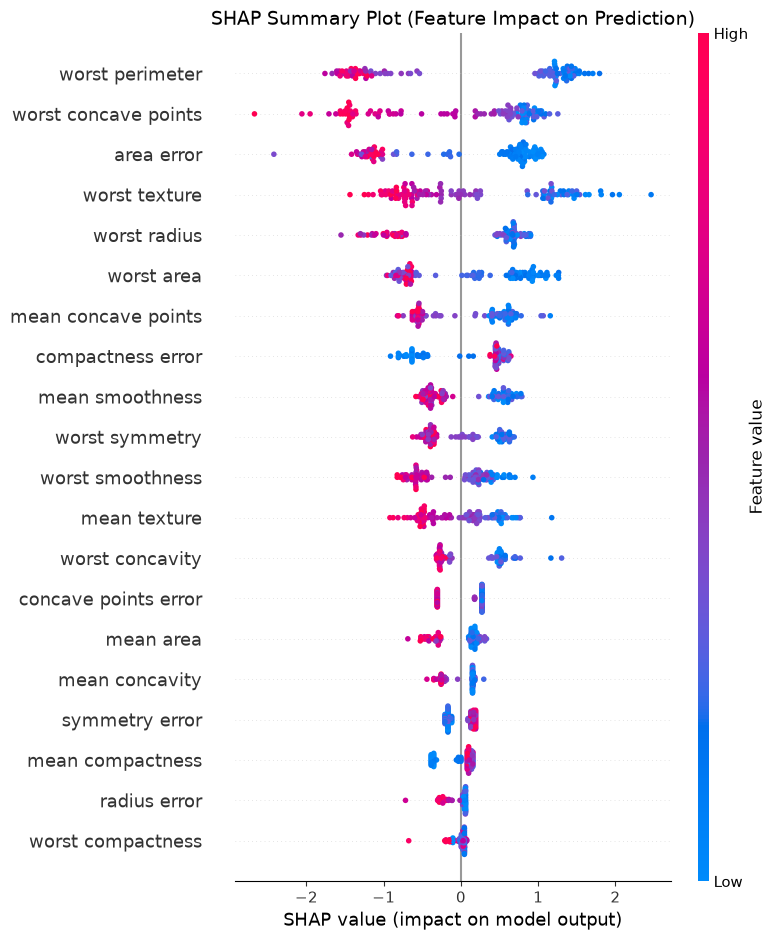

In [22]:
# 4. SHAP Summary Plot (Beeswarm)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Summary Plot (Feature Impact on Prediction)", fontsize=14)
plt.tight_layout()
plt.show()

Actual diagnosis for this patient: 0 (0=Malignant, 1=Benign)
Model prediction: 0


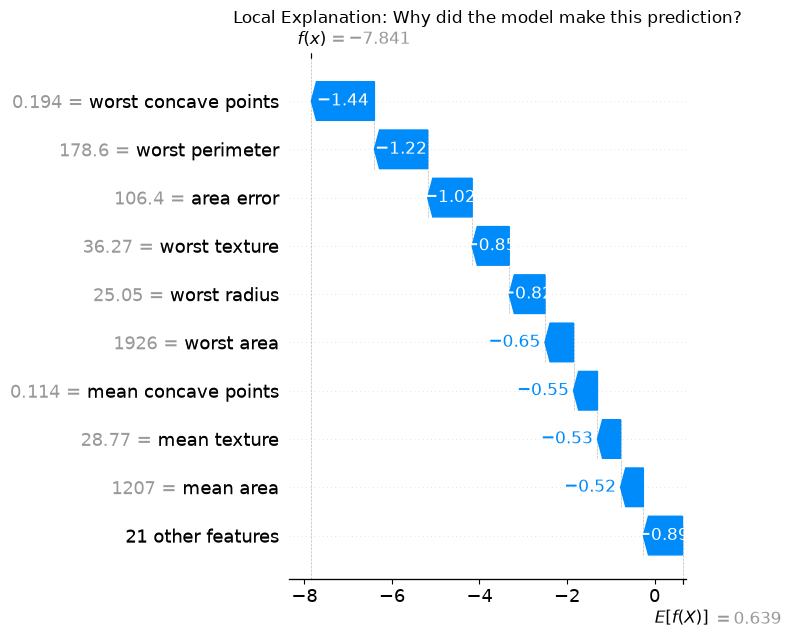

In [23]:
# 5. Local Explanation: Waterfall plot for a single prediction (Patient 0)
# We choose the first patient in X_test
patient_index = 0
patient_data = X_test.iloc[patient_index]

print(f"Actual diagnosis for this patient: {y_test.iloc[patient_index]} (0=Malignant, 1=Benign)")
print(f"Model prediction: {model.predict(patient_data.to_frame().T)[0]}")

# Create the waterfall plot
shap.waterfall_plot(shap.Explanation(values=shap_values[patient_index], 
                                     base_values=explainer.expected_value, 
                                     data=patient_data, 
                                     feature_names=X_test.columns.tolist()), show=False)
plt.title("Local Explanation: Why did the model make this prediction?", fontsize=12)
plt.tight_layout()
plt.show()

--- Top 10 Features Comparison ---
 Rank      Built-in Top 10          SHAP Top 10
    1         worst radius      worst perimeter
    2      worst perimeter worst concave points
    3 worst concave points           area error
    4        texture error        worst texture
    5  mean concave points         worst radius
    6    worst compactness           worst area
    7           worst area  mean concave points
    8            mean area    compactness error
    9        worst texture      mean smoothness
   10     smoothness error       worst symmetry


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8080\3643688132.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_builtin, x='Builtin_Importance', y='Feature', ax=axes[0], palette='Blues_r')
C:\Users\ASUS\AppData\Local\Temp\ipykernel_8080\3643688132.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_shap, x='SHAP_Importance', y='Feature', ax=axes[1], palette='Reds_r')


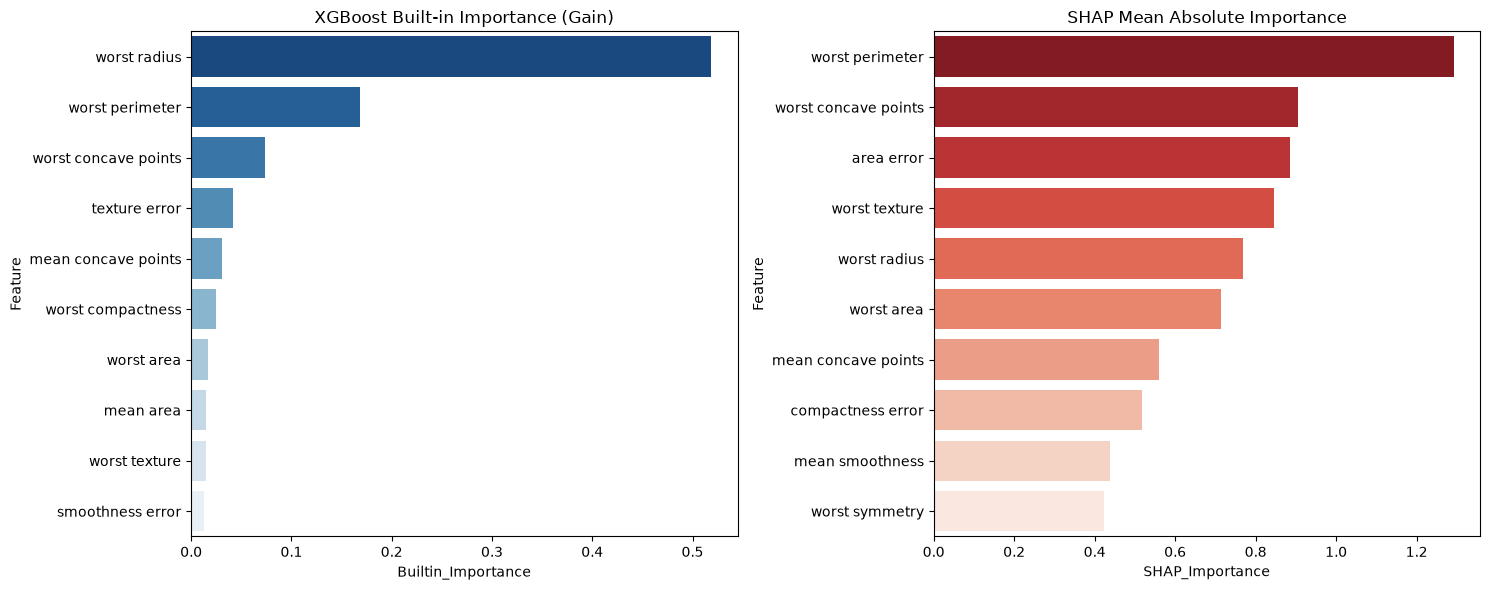

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Get Built-in XGBoost Importance
builtin_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Builtin_Importance': model.feature_importances_
}).sort_values(by='Builtin_Importance', ascending=False)

# 2. Get SHAP Mean Absolute Importance
shap_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'SHAP_Importance': np.abs(shap_values).mean(axis=0)
}).sort_values(by='SHAP_Importance', ascending=False)

# 3. Combine them side-by-side for the top 10 features
top_10_builtin = builtin_importance.head(10).reset_index(drop=True)
top_10_shap = shap_importance.head(10).reset_index(drop=True)
comparison = pd.DataFrame({
    'Rank': range(1, 11),
    'Built-in Top 10': top_10_builtin['Feature'],
    'SHAP Top 10': top_10_shap['Feature']
})
print("--- Top 10 Features Comparison ---")
print(comparison.to_string(index=False))

# 4. Visualize the difference
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=top_10_builtin, x='Builtin_Importance', y='Feature', ax=axes[0], palette='Blues_r')
axes[0].set_title('XGBoost Built-in Importance (Gain)')

sns.barplot(data=top_10_shap, x='SHAP_Importance', y='Feature', ax=axes[1], palette='Reds_r')
axes[1].set_title('SHAP Mean Absolute Importance')

plt.tight_layout()
plt.show()